# Test: bigger regional means under the maps

**Change** (`plotting/forcing_maps.py`):

| Before | After |
|---|---|
| under each map: `mean ≥45°N: +0.24 ± 0.04 W m⁻²`, 7.8 pt, all semibold | under each map: **+0.24** ± 0.04 W m⁻², `MEAN_FONTSIZE` = 13 pt; only the mean is bold (mathtext `\mathbf`), CI and units normal |
| region not in the title | subtitle under the figure title (`add_suptitle`): *Under the maps:* area-weighted mean over 45–90°N ± 95 % CI of the yearly means |
| contrast grids: 2.6 × 3.3 in per panel | 2.6 × 3.9 in per panel (`make_contrast_grid_figure` default; maps were squeezed by the bigger text) |
| colourbar ticks 7 pt, label 7 pt (per panel) / 8 pt (shared), line spacing 1.2 | ticks `CBAR_TICKSIZE` = 10 pt; label size unchanged (`CBAR_LABELSIZE` 7, `CBAR_LABELSIZE_SHARED` 8); label lines closer, `CBAR_LINESPACING` = 0.95 |
| six-panel forcing decomposition: figure 19 × 5.2 in | 19 × 4.4 in (`make_forcing_summary_figure` default; new `wspace` argument). Text sizes are in points, so the maps shrink and the gaps widen; a narrower figure made the long panel titles overlap |

The numbers themselves are unchanged (`regional_mean_interval`, the same 9 paired yearly differences).
One figure of each layout is drawn here, into `test_overall_map_mean_outputs/` (`results/figures/` is not touched):
1. Ghan decomposition: shared colourbar, 4 panels
2. Forcing summary: one colourbar per panel, 6 panels
3. Contrast grid: many small panels
4. % change maps

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
# 2001-2009 processed files were archived on 2026-10-28 (CLAUDE.md, run-version rule step 2 (i))
fm.POSTPROCESSED_DIR = fm.POSTPROCESSED_DIR / "2001-2009-pre-co2-fix"
START_YEAR, END_YEAR = 2001, 2009
OUT = Path.cwd() / "test_overall_map_mean_outputs"
common = dict(start_year=START_YEAR, end_year=END_YEAR, figdir=OUT, save=True)
print("data from", fm.POSTPROCESSED_DIR)
print("MEAN_FONTSIZE =", fm.MEAN_FONTSIZE)
print(fm.mean_subtitle(45))

data from /cluster/home/adelez/BOREAL-FOREST-EXPANSION/data/processed-data/postprocessing/2001-2009-pre-co2-fix
MEAN_FONTSIZE = 13
$\mathit{Under\ the\ maps}$: area-weighted mean over 45–90°N ± 95 % CI of the yearly means


Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_overall_map_mean_outputs/PD_ghan_LCC-CTRL_NET_2001_2009.png


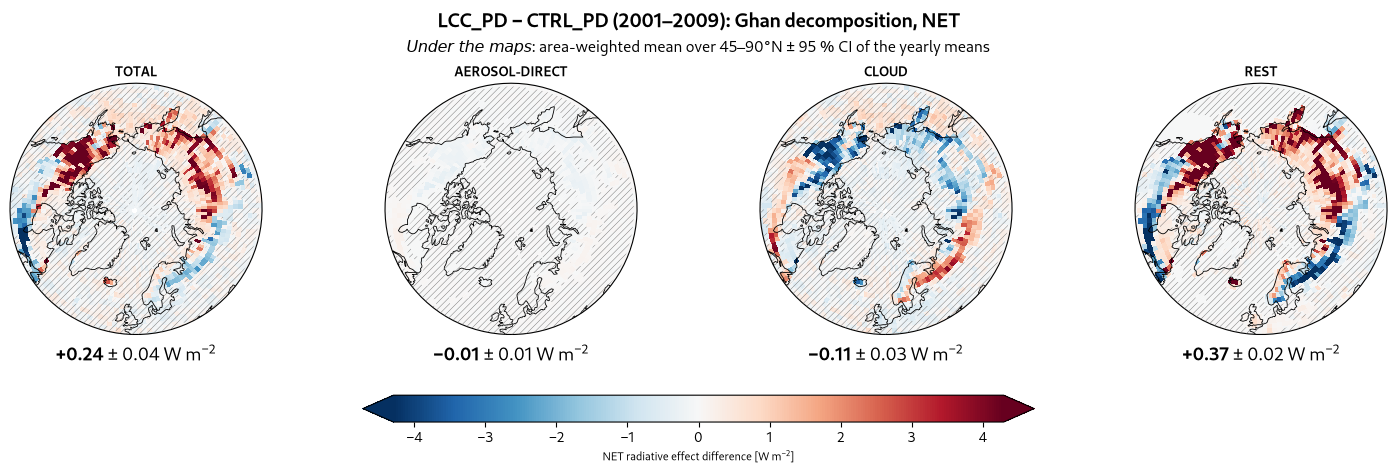

In [2]:
fig, axes = fm.make_ghan_figure("PD", "total", "NET", **common)
plt.show(); plt.close(fig)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_overall_map_mean_outputs/PD_forcing_decomposition_NET_2001_2009.png


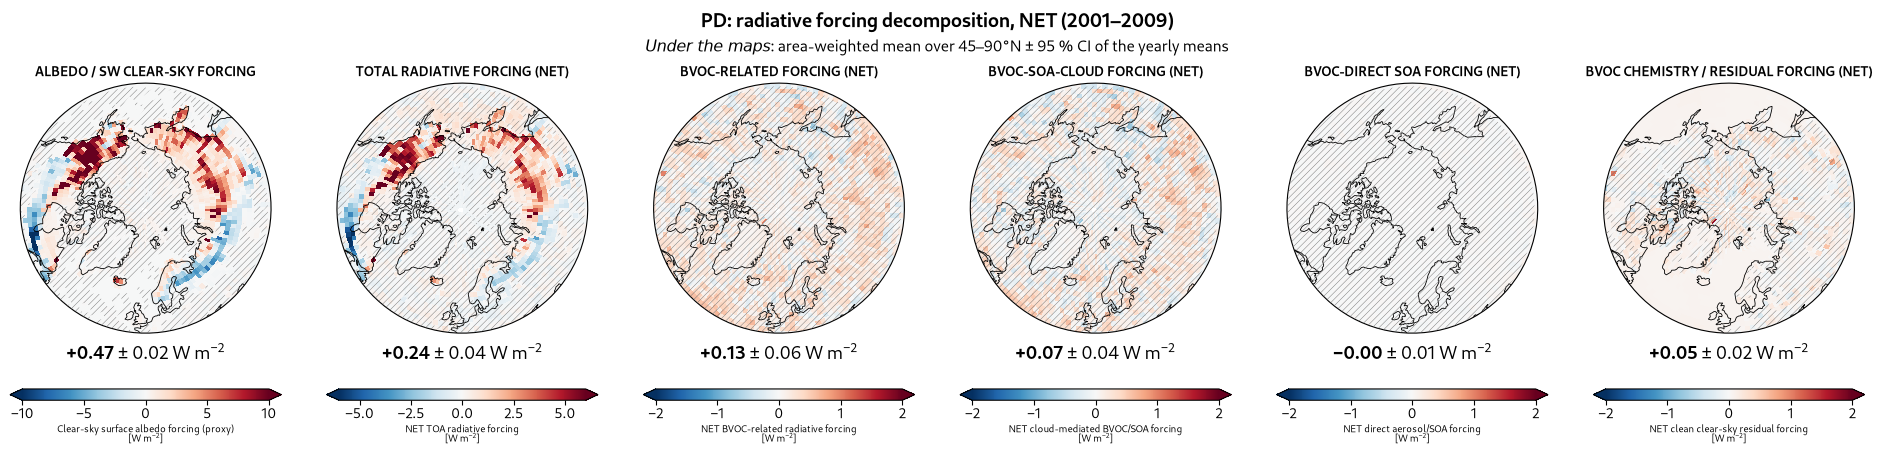

In [3]:
fig, axes = fm.make_forcing_summary_figure("PD", band="NET", **common)
plt.show(); plt.close(fig)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_overall_map_mean_outputs/contrast_grid_hydro_LCC-fBVOC_2001_2009.png


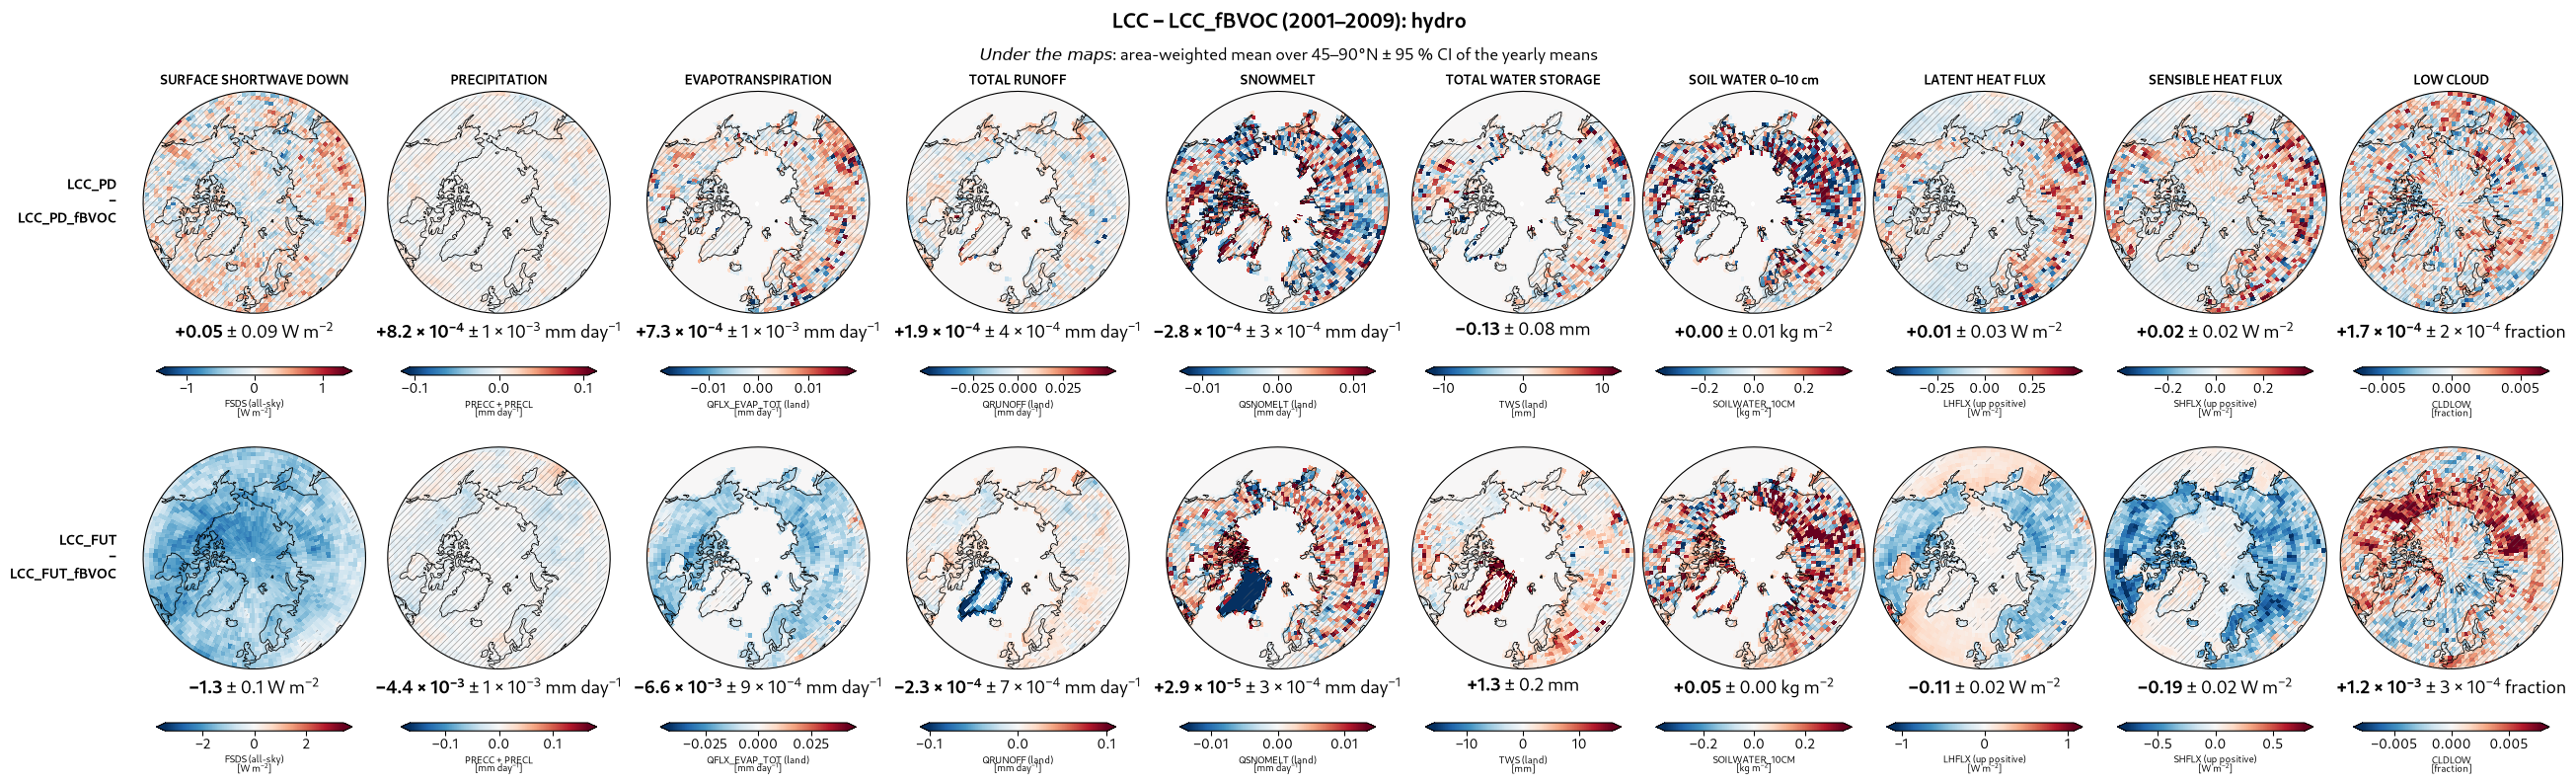

In [4]:
fig, axes = fm.make_contrast_grid_figure("LCC-fBVOC", fm.HYDRO_PANELS, "hydro", **common)
plt.show(); plt.close(fig)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/sandbox/test_overall_map_mean_outputs/bvoc_percent_change_maps_2001_2009.png


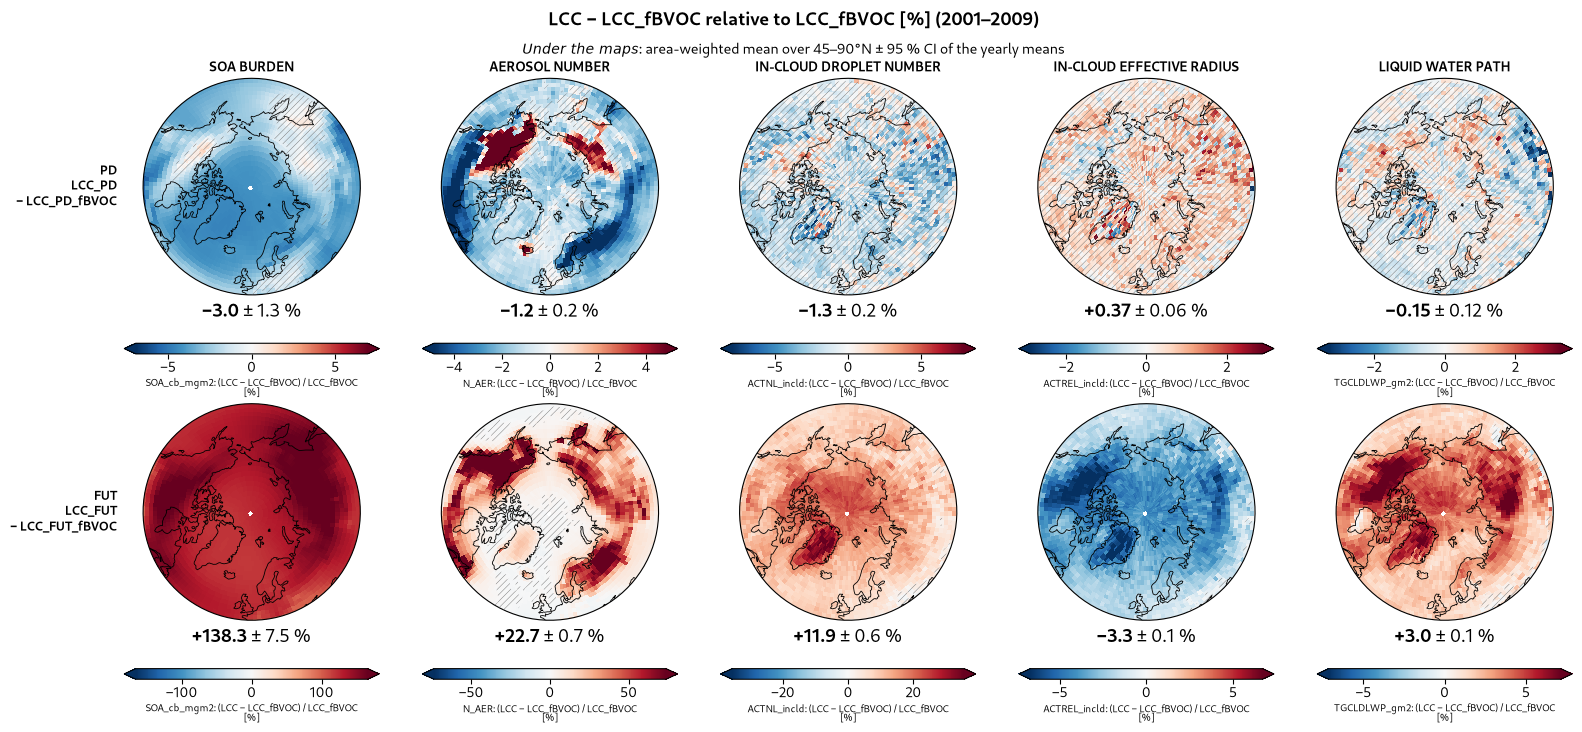

In [5]:
fig, axes = fm.make_percent_change_figure(START_YEAR, END_YEAR, figdir=OUT)
plt.show(); plt.close(fig)